# Predicting Post-Test Scores from Pre-Test Responses

## Research question

Can pre-test responses predict post-test scores more accurately than
simple baseline predictions?

This is an exploratory regression analysis. It predicts a numeric score,
rather than classifying participants as passing or failing.

## Data and scoring

Each track is modeled separately using the primary analysis participants
from the overall findings notebook.

Teachers, Scratch, Heat, and Flood use five questions.
Arduino uses Q1–Q4 while its Q5 answer key remains unresolved.

Inputs are pre-test correctness indicators, one per included question.
The outcome is the participant's post-test total.

Participant IDs are used only to match records. School, post-test answers,
and score changes are not model inputs.

## Evaluation

Five-fold cross-validation is repeated 20 times. Every participant receives
one held-out prediction per repetition. The participant being predicted
is excluded from model fitting for that prediction.

All methods use identical splits. Model settings are fixed in advance;
no hyperparameter search is performed.

Repeated evaluations reuse the same participants. They do not increase
the sample size, and variation between repetitions is not a confidence
interval.

In [1]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.base import clone
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown

ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "data" / "processed").is_dir()),
    None,
)

if ROOT is None:
    raise FileNotFoundError("Cannot locate the project data/processed folder.")

DATA = ROOT / "data" / "processed"
OVERALL = ROOT / "outputs" / "tables" / "overall"
FIGURES = ROOT / "outputs" / "figures" / "prediction"
TABLES = ROOT / "outputs" / "tables" / "prediction"

FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "teachers": ("Teachers", 5),
    "scratch": ("Scratch", 5),
    "microbit_heat": ("micro:bit Heat", 5),
    "microbit_flood": ("micro:bit Flood", 5),
    "arduino": ("Arduino", 4),
}

SEED = 42
N_SPLITS = 5
N_REPEATS = 20

METHODS = [
    "No change",
    "Training mean",
    "Ridge",
    "Small tree",
]

COLORS = {
    "No change": "#969696",
    "Training mean": "#4C78A8",
    "Ridge": "#7952B3",
    "Small tree": "#E88932",
}

plt.rcParams.update({
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def save_figure(fig, filename):
    fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)

Python: 3.14.2
scikit-learn: 1.9.1


In [3]:
primary_path = OVERALL / "overall_primary_participant_scores.csv"

if not primary_path.exists():
    raise FileNotFoundError(
        "Run the export cell in 07_overall_findings.ipynb first."
    )

primary = pd.read_csv(
    primary_path,
    dtype={"participant_id": "string"},
)

reference = pd.read_csv(DATA / "question_reference.csv")
reference["phase"] = (
    reference["phase"].astype(str).str.strip().str.lower()
)
reference["question_number"] = pd.to_numeric(
    reference["question"].astype(str).str.extract(r"(\d+)", expand=False),
    errors="raise",
).astype(int)
reference["answer_key_raw"] = (
    reference["answer_key_raw"].astype("string").str.strip().str.upper()
)

model_data = {}
coverage_rows = []
feature_frames = []

for track, (label, question_count) in CONFIG.items():
    frame = pd.read_csv(
        DATA / f"{track}.csv",
        dtype={"participant_id": "string"},
    )

    if frame["participant_id"].fillna("").str.strip().eq("").any():
        raise ValueError(f"{label}: missing participant IDs.")
    if frame["participant_id"].duplicated().any():
        raise ValueError(f"{label}: duplicate participant IDs.")
    if not frame["track"].eq(track).all():
        raise ValueError(f"{label}: unexpected track values.")

    cols = [
        f"{phase}_q{q}"
        for phase in ["pre", "post"]
        for q in range(1, question_count + 1)
    ]

    answers = frame[cols].apply(
        lambda col: col.astype("string").str.strip().str.upper()
    )
    included = answers.isin(list("ABCD")).all(axis=1)

    keys = reference.loc[
        reference["track"].eq(track)
        & reference["question_number"].le(question_count)
    ].copy()

    expected_keys = {
        (phase, q)
        for phase in ["pre", "post"]
        for q in range(1, question_count + 1)
    }

    if (
        len(keys) != 2 * question_count
        or set(zip(keys["phase"], keys["question_number"])) != expected_keys
        or not keys["answer_key_raw"].isin(list("ABCD")).all()
    ):
        raise ValueError(f"{label}: invalid or unresolved primary keys.")

    key_map = keys.set_index(
        ["phase", "question_number"]
    )["answer_key_raw"]

    selected = frame.loc[included].copy()
    selected_answers = answers.loc[included]

    # Each feature is available before the post-test.
    X = pd.DataFrame({
        f"pre_q{q}_correct": (
            selected_answers[f"pre_q{q}"]
            .eq(key_map[("pre", q)]).astype(int).to_numpy()
        )
        for q in range(1, question_count + 1)
    })

    y = sum(
        selected_answers[f"post_q{q}"]
        .eq(key_map[("post", q)]).astype(int).to_numpy()
        for q in range(1, question_count + 1)
    ).astype(float)

    pre_total = X.sum(axis=1).to_numpy(dtype=float)
    ids = selected["participant_id"].to_numpy()

    # Match notebook 07, including membership and scoring.
    saved = primary.loc[primary["track"].eq(track)].copy()

    if saved["participant_id"].duplicated().any():
        raise ValueError(f"{label}: duplicate IDs in notebook 07 export.")

    if set(ids) != set(saved["participant_id"]):
        raise ValueError(
            f"{label}: participant selection differs from notebook 07. "
            "Rerun notebook 07."
        )

    saved = saved.set_index("participant_id").loc[ids]

    if not (
        saved["questions_scored"].eq(question_count).all()
        and np.allclose(saved["pre_correct"], pre_total)
        and np.allclose(saved["post_correct"], y)
    ):
        raise ValueError(f"{label}: scores differ from notebook 07.")

    if len(y) < N_SPLITS:
        raise ValueError(f"{label}: too few participants for evaluation.")

    model_data[track] = {
        "label": label,
        "questions": question_count,
        "ids": ids,
        "X": X,
        "y": y,
        "pre_total": pre_total,
    }

    coverage_rows.append({
        "track": track,
        "track_label": label,
        "source_n": len(frame),
        "model_n": len(y),
        "excluded_n": len(frame) - len(y),
        "questions_scored": question_count,
        "features": X.shape[1],
    })

    features_export = X.copy()
    features_export.insert(0, "participant_id", ids)
    features_export.insert(0, "track", track)
    features_export["post_correct_target"] = y
    feature_frames.append(features_export)

modeling_table = pd.concat(feature_frames, ignore_index=True)
coverage = pd.DataFrame(coverage_rows)

display(coverage)
print("All participant selections and scores match notebook 07.")

,track,track_label,source_n,model_n,excluded_n,questions_scored,features
0,teachers,Teachers,29,29,0,5,5
1,scratch,Scratch,22,22,0,5,5
2,microbit_heat,micro:bit Heat,25,25,0,5,5
3,microbit_flood,micro:bit Flood,26,25,1,5,5
4,arduino,Arduino,27,26,1,4,4


All participant selections and scores match notebook 07.


## Models and performance measures

Two baselines are compared with Ridge regression and a small decision tree.

The training-mean baseline learns its mean from the training fold only.
Ridge scaling is also fitted within the training fold.

Predictions are restricted to the valid score range, from zero to the
number of included questions. Predictions remain fractional; they are
not rounded before evaluation.

### Metrics

- **MAE:** Average absolute prediction error, measured in correct answers.
  An MAE of 0.60 means predictions miss the actual score by 0.60 answers
  on average.
- **MAE in percentage points:** MAE divided by the question count,
  multiplied by 100.
- **RMSE:** An error measure that gives more weight to large misses.
- **R²:** A descriptive measure relative to the variation in observed
  outcomes. Negative values indicate poor predictive performance.
- **Within one answer:** Percentage of predictions no more than one
  answer away from the actual score. This is a tolerance measure,
  not exact classification accuracy.

Lower MAE and RMSE are better. The primary comparison is whether models
reduce MAE relative to both baselines.

In [4]:
model_templates = {
    "Ridge": make_pipeline(
        StandardScaler(),
        Ridge(alpha=10.0),
    ),
    "Small tree": DecisionTreeRegressor(
        max_depth=2,
        min_samples_leaf=5,
        random_state=SEED,
    ),
}

prediction_rows = []

for track, data in model_data.items():
    X = data["X"]
    y = data["y"]
    question_count = data["questions"]

    for repeat in range(N_REPEATS):
        splitter = KFold(
            n_splits=N_SPLITS,
            shuffle=True,
            random_state=SEED + repeat,
        )

        for fold, (train_idx, test_idx) in enumerate(
            splitter.split(X), start=1
        ):
            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]
            y_train = y[train_idx]

            fold_predictions = {
                "No change": data["pre_total"][test_idx],
                "Training mean": np.full(
                    len(test_idx), y_train.mean()
                ),
            }

            for name, template in model_templates.items():
                model = clone(template)
                model.fit(X_train, y_train)
                fold_predictions[name] = model.predict(X_test)

            for method, predictions in fold_predictions.items():
                predictions = np.clip(predictions, 0, question_count)

                for position, predicted in zip(test_idx, predictions):
                    actual = float(y[position])

                    prediction_rows.append({
                        "track": track,
                        "participant_id": data["ids"][position],
                        "repeat": repeat + 1,
                        "fold": fold,
                        "method": method,
                        "questions_scored": question_count,
                        "pre_correct": float(data["pre_total"][position]),
                        "actual_post": actual,
                        "predicted_post": float(predicted),
                        "error": float(predicted - actual),
                        "absolute_error": float(abs(predicted - actual)),
                    })

    print(f"Finished: {data['label']}")

predictions = pd.DataFrame(prediction_rows)

# Each participant must have one held-out prediction per method per repeat.
if predictions.duplicated(
    ["track", "participant_id", "repeat", "method"]
).any():
    raise ValueError("Duplicate held-out predictions detected.")

prediction_counts = predictions.groupby(
    ["track", "participant_id", "method"]
).size()

if not prediction_counts.eq(N_REPEATS).all():
    raise ValueError("Missing held-out predictions detected.")

print("Evaluation complete. Every participant was held out once per repetition.")

Finished: Teachers
Finished: Scratch
Finished: micro:bit Heat
Finished: micro:bit Flood
Finished: Arduino
Evaluation complete. Every participant was held out once per repetition.


In [5]:
metric_rows = []

# Score each complete repetition, rather than averaging unequal fold sizes.
for (track, repeat, method), group in predictions.groupby(
    ["track", "repeat", "method"], sort=False
):
    actual = group["actual_post"].to_numpy()
    predicted = group["predicted_post"].to_numpy()
    question_count = int(group["questions_scored"].iloc[0])

    mae = mean_absolute_error(actual, predicted)

    metric_rows.append({
        "track": track,
        "repeat": repeat,
        "method": method,
        "n": len(group),
        "mae_answers": mae,
        "mae_pp": mae / question_count * 100,
        "rmse_answers": np.sqrt(mean_squared_error(actual, predicted)),
        "r2": (
            r2_score(actual, predicted)
            if np.var(actual) > 0 else np.nan
        ),
        "within_one_pct": (
            np.abs(predicted - actual) <= 1 + 1e-10
        ).mean() * 100,
    })

repeat_metrics = pd.DataFrame(metric_rows)

metrics = (
    repeat_metrics.groupby(["track", "method"], sort=False)
    .agg(
        n=("n", "first"),
        mae_answers=("mae_answers", "mean"),
        mae_repeat_sd=("mae_answers", "std"),
        mae_pp=("mae_pp", "mean"),
        rmse_answers=("rmse_answers", "mean"),
        r2=("r2", "mean"),
        within_one_pct=("within_one_pct", "mean"),
    )
    .reset_index()
)

display(metrics.round(3))

baseline_rows = []

for track in CONFIG:
    track_metrics = metrics.loc[metrics["track"].eq(track)].set_index("method")
    by_repeat = (
        repeat_metrics.loc[repeat_metrics["track"].eq(track)]
        .pivot(index="repeat", columns="method", values="mae_answers")
    )

    for method in ["Ridge", "Small tree"]:
        model_mae = track_metrics.loc[method, "mae_answers"]

        baseline_rows.append({
            "track": track,
            "model": method,
            "mae_answers": model_mae,
            "mae_reduction_vs_no_change": (
                track_metrics.loc["No change", "mae_answers"] - model_mae
            ),
            "mae_reduction_vs_training_mean": (
                track_metrics.loc["Training mean", "mae_answers"] - model_mae
            ),
            "repeats_better_than_both_pct": (
                (by_repeat[method] < by_repeat["No change"])
                & (by_repeat[method] < by_repeat["Training mean"])
            ).mean() * 100,
        })

baseline_comparison = pd.DataFrame(baseline_rows)
display(baseline_comparison.round(3))

print("Positive MAE reduction means the model had lower error.")
print("Repeat SD describes split variability, not a confidence interval.")

,track,method,n,mae_answers,mae_repeat_sd,mae_pp,rmse_answers,r2,within_one_pct
0,teachers,No change,29,1.586,0.000,31.724,2.034,-1.114,58.621
1,teachers,Training mean,29,1.269,0.035,25.374,1.455,-0.083,50.517
2,teachers,Ridge,29,1.151,0.070,23.017,1.436,-0.056,40.345
3,teachers,Small tree,29,1.107,0.072,22.149,1.349,0.068,42.241
4,scratch,No change,22,1.545,0.000,30.909,1.706,-1.682,59.091
5,scratch,Training mean,22,0.825,0.030,16.497,1.095,-0.107,63.409
6,scratch,Ridge,22,0.753,0.049,15.070,1.135,-0.189,65.000
7,scratch,Small tree,22,0.730,0.061,14.606,1.065,-0.048,65.682
8,microbit_heat,No change,25,0.880,0.000,17.600,1.166,-0.316,84.000
9,microbit_heat,Training mean,25,0.784,0.018,15.688,1.061,-0.090,65.000


,track,model,mae_answers,mae_reduction_vs_no_change,mae_reduction_vs_training_mean,repeats_better_than_both_pct
0,teachers,Ridge,1.151,0.435,0.118,95.0
1,teachers,Small tree,1.107,0.479,0.161,95.0
2,scratch,Ridge,0.753,0.792,0.071,95.0
3,scratch,Small tree,0.730,0.815,0.095,90.0
4,microbit_heat,Ridge,0.862,0.018,-0.077,0.0
5,microbit_heat,Small tree,0.819,0.061,-0.035,10.0
6,microbit_flood,Ridge,0.689,-0.089,0.015,0.0
7,microbit_flood,Small tree,0.692,-0.092,0.012,0.0
8,arduino,Ridge,0.916,0.161,-0.048,0.0
9,arduino,Small tree,0.905,0.172,-0.038,10.0


Positive MAE reduction means the model had lower error.
Repeat SD describes split variability, not a confidence interval.


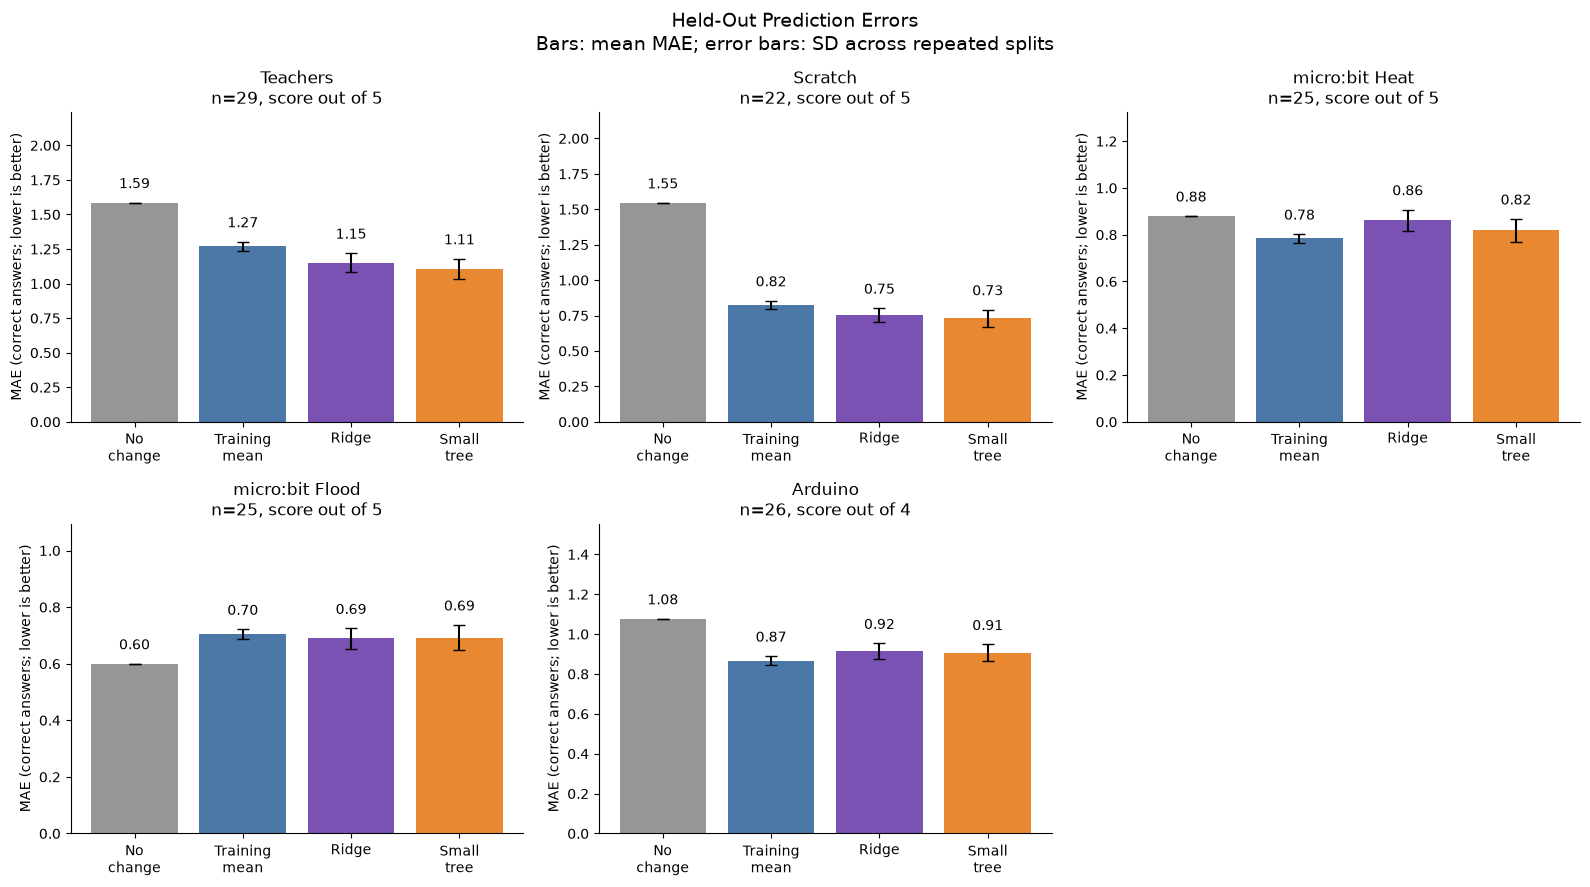

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for ax, track in zip(axes, CONFIG):
    selected = (
        metrics.loc[metrics["track"].eq(track)]
        .set_index("method")
        .loc[METHODS]
    )

    bars = ax.bar(
        np.arange(len(METHODS)),
        selected["mae_answers"],
        yerr=selected["mae_repeat_sd"],
        capsize=4,
        color=[COLORS[method] for method in METHODS],
    )

    ax.bar_label(bars, fmt="%.2f", padding=8)
    ax.set_xticks(
        np.arange(len(METHODS)),
        ["No\nchange", "Training\nmean", "Ridge", "Small\ntree"],
    )

    upper = (
        selected["mae_answers"] + selected["mae_repeat_sd"]
    ).max()

    ax.set_ylim(0, upper * 1.35 + 0.1)
    ax.set_ylabel("MAE (correct answers; lower is better)")
    ax.set_title(
        f"{CONFIG[track][0]}\n"
        f"n={len(model_data[track]['y'])}, "
        f"score out of {CONFIG[track][1]}"
    )

axes[-1].axis("off")

fig.suptitle(
    "Held-Out Prediction Errors\n"
    "Bars: mean MAE; error bars: SD across repeated splits",
    fontsize=14,
)

save_figure(fig, "01_model_mae_comparison.png")

## Predicted versus actual scores

The next figures use the first pre-specified cross-validation repetition
for Ridge regression. Every plotted prediction was made while that
participant was excluded from model fitting.

Ridge is shown consistently across tracks rather than selecting a
different model after inspecting each track's results.

Points on the diagonal represent perfect predictions. Repeated
actual/predicted pairs are represented by larger markers.

Residuals are predicted minus actual scores. Positive values indicate
overprediction; negative values indicate underprediction.

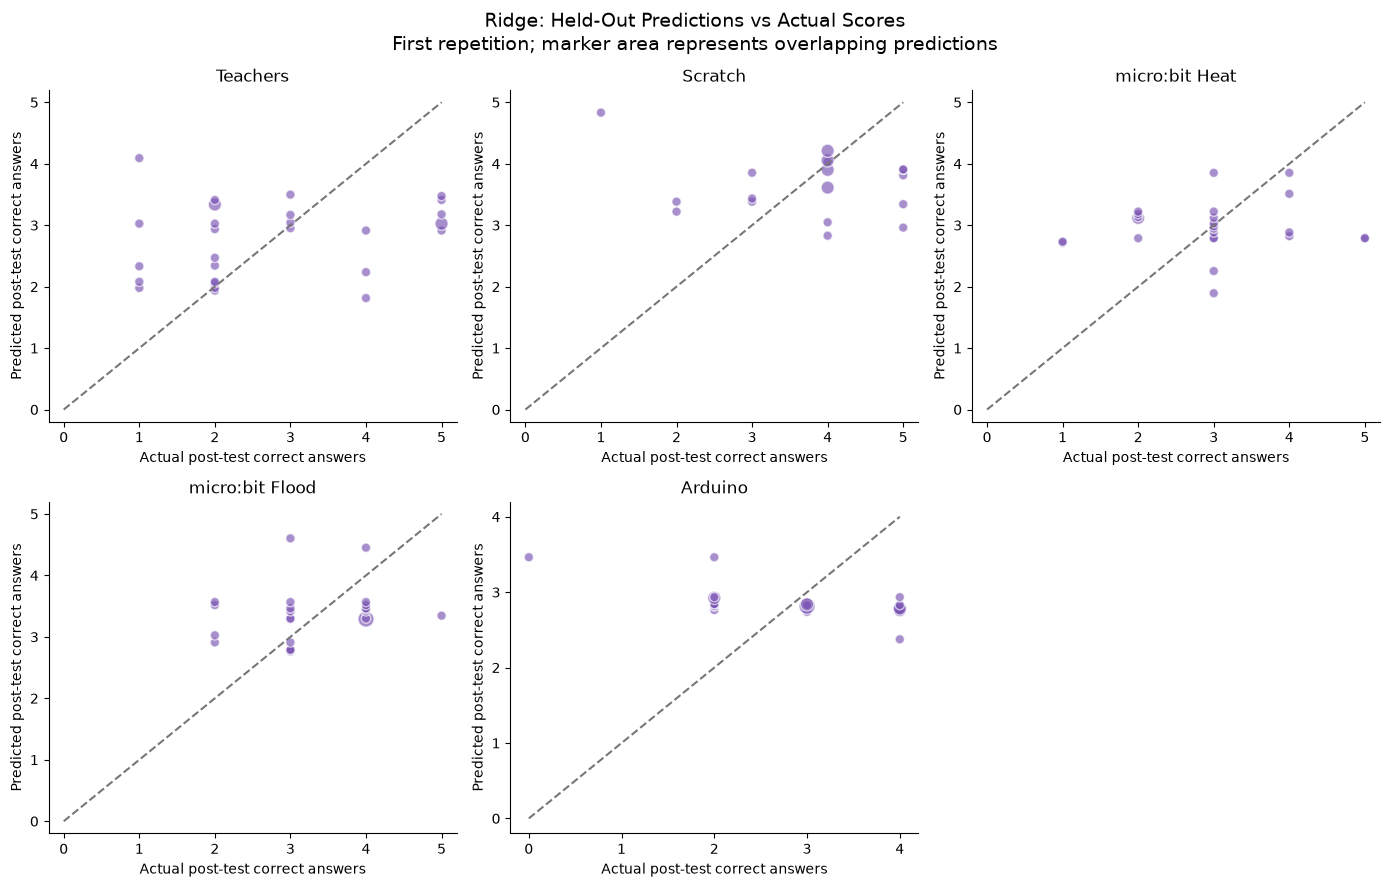

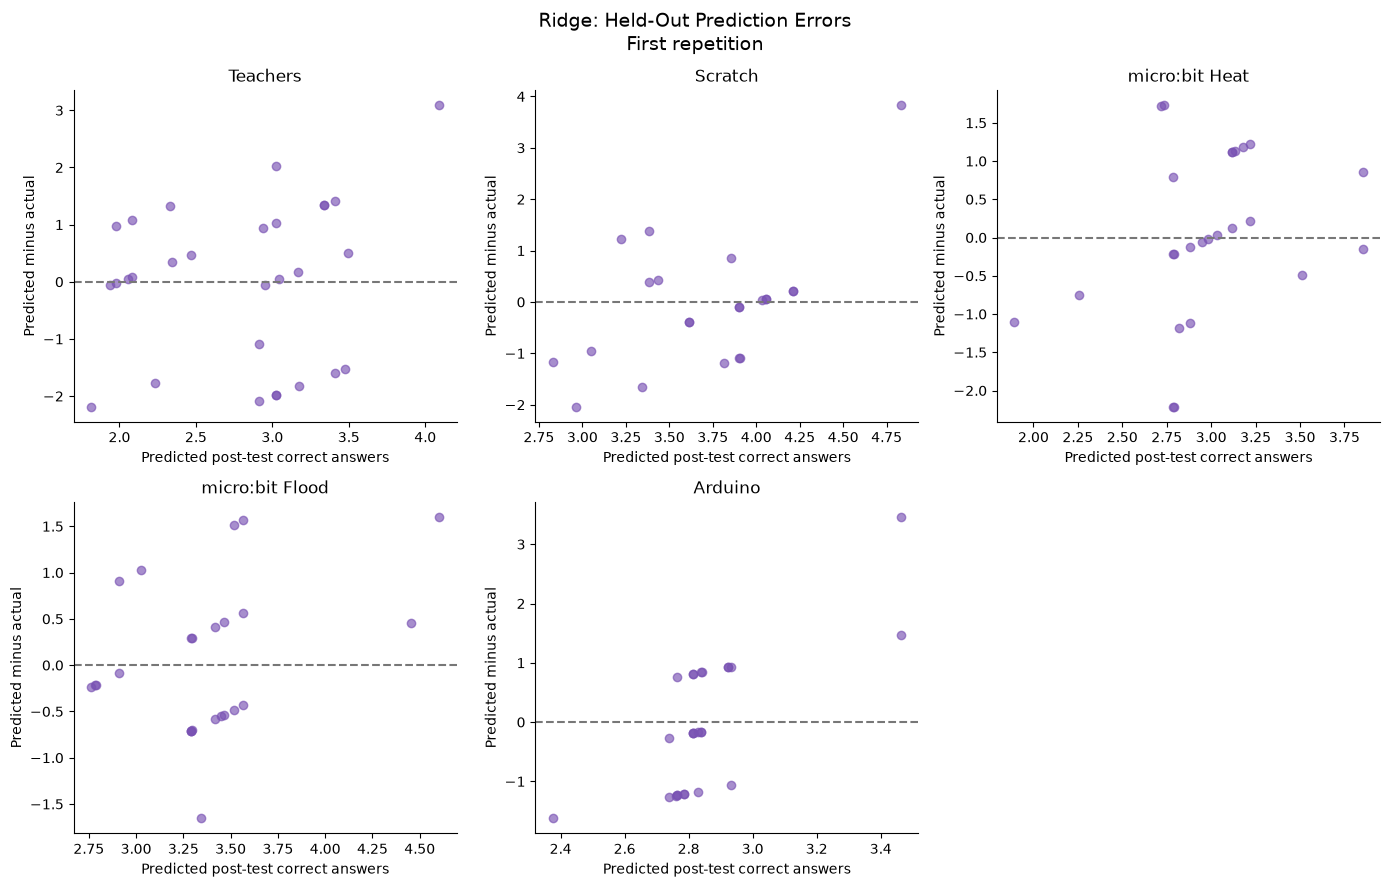

In [7]:
ridge_example = predictions.loc[
    predictions["method"].eq("Ridge")
    & predictions["repeat"].eq(1)
].copy()

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

for ax, track in zip(axes, CONFIG):
    group = ridge_example.loc[ridge_example["track"].eq(track)]
    maximum = CONFIG[track][1]

    points = (
        group.groupby(["actual_post", "predicted_post"])
        .size().reset_index(name="count")
    )

    ax.scatter(
        points["actual_post"],
        points["predicted_post"],
        s=points["count"] * 45,
        color=COLORS["Ridge"],
        alpha=0.65,
        edgecolors="white",
    )
    ax.plot([0, maximum], [0, maximum], "--", color="#777777")
    ax.set_xlim(-0.2, maximum + 0.2)
    ax.set_ylim(-0.2, maximum + 0.2)
    ax.set_xticks(range(maximum + 1))
    ax.set_yticks(range(maximum + 1))
    ax.set_xlabel("Actual post-test correct answers")
    ax.set_ylabel("Predicted post-test correct answers")
    ax.set_title(CONFIG[track][0])

axes[-1].axis("off")
fig.suptitle(
    "Ridge: Held-Out Predictions vs Actual Scores\n"
    "First repetition; marker area represents overlapping predictions",
    fontsize=14,
)
save_figure(fig, "02_ridge_predicted_vs_actual.png")

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
axes = axes.ravel()

for ax, track in zip(axes, CONFIG):
    group = ridge_example.loc[ridge_example["track"].eq(track)]

    ax.scatter(
        group["predicted_post"],
        group["error"],
        color=COLORS["Ridge"],
        alpha=0.65,
    )
    ax.axhline(0, linestyle="--", color="#777777")
    ax.set_xlabel("Predicted post-test correct answers")
    ax.set_ylabel("Predicted minus actual")
    ax.set_title(CONFIG[track][0])

axes[-1].axis("off")
fig.suptitle(
    "Ridge: Held-Out Prediction Errors\nFirst repetition",
    fontsize=14,
)
save_figure(fig, "03_ridge_residuals.png")

In [8]:
# One row per participant per method from the first repetition.
example_predictions = predictions.loc[
    predictions["repeat"].eq(1)
].copy()

example_predictions["actual_post_pct"] = (
    example_predictions["actual_post"]
    / example_predictions["questions_scored"] * 100
)
example_predictions["predicted_post_pct"] = (
    example_predictions["predicted_post"]
    / example_predictions["questions_scored"] * 100
)
example_predictions["within_one_answer"] = (
    example_predictions["absolute_error"] <= 1 + 1e-10
)

display(
    example_predictions.loc[
        example_predictions["method"].eq("Ridge"),
        [
            "track",
            "participant_id",
            "pre_correct",
            "actual_post",
            "predicted_post",
            "absolute_error",
            "within_one_answer",
        ],
    ].round(3)
)

,track,participant_id,pre_correct,actual_post,predicted_post,absolute_error,within_one_answer
12,teachers,4AC5DA14,1.0,4.0,2.235,1.765,False
13,teachers,1206412D,1.0,5.0,2.913,2.087,False
14,teachers,8BFF8B93,0.0,1.0,1.979,0.979,True
15,teachers,9B19AB59,2.0,3.0,2.952,0.048,True
16,teachers,634CF80F,1.0,4.0,2.913,1.087,False
...,...,...,...,...,...,...,...
8174,arduino,B7CC4E60,3.0,4.0,2.761,1.239,False
8175,arduino,CC13DF66,3.0,4.0,2.934,1.066,False
8176,arduino,CD7701D6,2.0,3.0,2.739,0.261,True
8177,arduino,BBD5AF1E,3.0,2.0,2.934,0.934,True


In [9]:
sections = []

for track, (label, question_count) in CONFIG.items():
    track_metrics = (
        metrics.loc[metrics["track"].eq(track)].set_index("method")
    )

    lines = []

    for method in METHODS:
        row = track_metrics.loc[method]
        lines.append(
            f"- **{method}:** MAE **{row['mae_answers']:.3f} answers** "
            f"({row['mae_pp']:.2f} percentage points); "
            f"RMSE **{row['rmse_answers']:.3f}**; "
            f"R² **{row['r2']:.3f}**; "
            f"within one answer **{row['within_one_pct']:.1f}%**."
        )

    model_comments = []

    for method in ["Ridge", "Small tree"]:
        comparison = baseline_comparison.loc[
            baseline_comparison["track"].eq(track)
            & baseline_comparison["model"].eq(method)
        ].iloc[0]

        beats_both = (
            comparison["mae_reduction_vs_no_change"] > 0
            and comparison["mae_reduction_vs_training_mean"] > 0
        )

        conclusion = (
            "had lower average MAE than both baselines"
            if beats_both
            else "did not have lower average MAE than both baselines"
        )

        model_comments.append(
            f"**{method} {conclusion}.** Its MAE reduction relative to "
            f"the training-mean baseline was "
            f"**{comparison['mae_reduction_vs_training_mean']:+.3f} answers**. "
            f"It beat both baselines in "
            f"**{comparison['repeats_better_than_both_pct']:.0f}%** "
            f"of repetitions."
        )

    sections.append(
        f"### {label}\n\n"
        f"Sample: **{len(model_data[track]['y'])} participants**; "
        f"target: post-test score out of **{question_count}**.\n\n"
        + "\n".join(lines)
        + "\n\n"
        + "\n\n".join(model_comments)
    )

findings_md = (
    "## Prediction results\n\n"
    "The results below use held-out predictions from repeated "
    "five-fold cross-validation. Metrics are averaged across complete "
    "repetitions.\n\n"
    + "\n\n".join(sections)
    + """

## What these results mean

A model is useful only if its errors improve on appropriate baselines.
Beating the no-change baseline alone may simply reflect an overall shift
between pre-test and post-test scores. Beating the training-mean baseline
provides stronger evidence that pre-test responses contribute predictive
information in this evaluation.

Small differences between methods should be interpreted cautiously.
The same participants are reused across repetitions, so repetition
counts and error-bar variation are not independent statistical evidence.

If a baseline performs as well as or better than the models, that is a
valid finding. These data may not support useful individual prediction
from pre-test correctness alone.

## Limits of this analysis

Each track contains only 22–29 participants before exclusions. Evaluation
uses participants from the same observed workshop group and does not
establish performance for future cohorts or previously unseen schools.

Random participant splits may place participants from the same school
in both training and validation folds. Generalization to new schools
would require a separate school-grouped evaluation with sufficient data.

The models use correctness indicators, which do not distinguish between
different incorrect answer choices. The assessments are short, and
Teachers and Arduino use different pre/post questions.

Arduino predictions concern Q1–Q4 only. Unresolved post-test outcomes
are excluded from evaluation rather than assigned invented targets.

Model settings were fixed in advance. Any model selected after inspecting
these results would require further validation before being called a
validated best model.

## Conclusions for reporting

Report the prediction errors, the baseline comparisons, the sample size,
and the scoring definition together.

Do not describe MAE or within-one-answer rates as exact prediction
accuracy. Do not convert MAE into an invented accuracy percentage.

This analysis evaluates prediction from pre-test responses. It does not
estimate the causal effect of the workshop, and no model has yet been
validated on an independent future cohort.
"""
)

display(Markdown(findings_md))

## Prediction results

The results below use held-out predictions from repeated five-fold cross-validation. Metrics are averaged across complete repetitions.

### Teachers

Sample: **29 participants**; target: post-test score out of **5**.

- **No change:** MAE **1.586 answers** (31.72 percentage points); RMSE **2.034**; R² **-1.114**; within one answer **58.6%**.
- **Training mean:** MAE **1.269 answers** (25.37 percentage points); RMSE **1.455**; R² **-0.083**; within one answer **50.5%**.
- **Ridge:** MAE **1.151 answers** (23.02 percentage points); RMSE **1.436**; R² **-0.056**; within one answer **40.3%**.
- **Small tree:** MAE **1.107 answers** (22.15 percentage points); RMSE **1.349**; R² **0.068**; within one answer **42.2%**.

**Ridge had lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **+0.118 answers**. It beat both baselines in **95%** of repetitions.

**Small tree had lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **+0.161 answers**. It beat both baselines in **95%** of repetitions.

### Scratch

Sample: **22 participants**; target: post-test score out of **5**.

- **No change:** MAE **1.545 answers** (30.91 percentage points); RMSE **1.706**; R² **-1.682**; within one answer **59.1%**.
- **Training mean:** MAE **0.825 answers** (16.50 percentage points); RMSE **1.095**; R² **-0.107**; within one answer **63.4%**.
- **Ridge:** MAE **0.753 answers** (15.07 percentage points); RMSE **1.135**; R² **-0.189**; within one answer **65.0%**.
- **Small tree:** MAE **0.730 answers** (14.61 percentage points); RMSE **1.065**; R² **-0.048**; within one answer **65.7%**.

**Ridge had lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **+0.071 answers**. It beat both baselines in **95%** of repetitions.

**Small tree had lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **+0.095 answers**. It beat both baselines in **90%** of repetitions.

### micro:bit Heat

Sample: **25 participants**; target: post-test score out of **5**.

- **No change:** MAE **0.880 answers** (17.60 percentage points); RMSE **1.166**; R² **-0.316**; within one answer **84.0%**.
- **Training mean:** MAE **0.784 answers** (15.69 percentage points); RMSE **1.061**; R² **-0.090**; within one answer **65.0%**.
- **Ridge:** MAE **0.862 answers** (17.24 percentage points); RMSE **1.074**; R² **-0.117**; within one answer **56.2%**.
- **Small tree:** MAE **0.819 answers** (16.38 percentage points); RMSE **1.092**; R² **-0.155**; within one answer **59.8%**.

**Ridge did not have lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **-0.077 answers**. It beat both baselines in **0%** of repetitions.

**Small tree did not have lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **-0.035 answers**. It beat both baselines in **10%** of repetitions.

### micro:bit Flood

Sample: **25 participants**; target: post-test score out of **5**.

- **No change:** MAE **0.600 answers** (12.00 percentage points); RMSE **0.872**; R² **-0.231**; within one answer **92.0%**.
- **Training mean:** MAE **0.704 answers** (14.09 percentage points); RMSE **0.822**; R² **-0.095**; within one answer **80.0%**.
- **Ridge:** MAE **0.689 answers** (13.79 percentage points); RMSE **0.809**; R² **-0.063**; within one answer **80.8%**.
- **Small tree:** MAE **0.692 answers** (13.84 percentage points); RMSE **0.806**; R² **-0.058**; within one answer **82.4%**.

**Ridge did not have lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **+0.015 answers**. It beat both baselines in **0%** of repetitions.

**Small tree did not have lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **+0.012 answers**. It beat both baselines in **0%** of repetitions.

### Arduino

Sample: **26 participants**; target: post-test score out of **4**.

- **No change:** MAE **1.077 answers** (26.92 percentage points); RMSE **1.301**; R² **-0.651**; within one answer **84.6%**.
- **Training mean:** MAE **0.867 answers** (21.68 percentage points); RMSE **1.052**; R² **-0.081**; within one answer **59.2%**.
- **Ridge:** MAE **0.916 answers** (22.89 percentage points); RMSE **1.127**; R² **-0.240**; within one answer **59.2%**.
- **Small tree:** MAE **0.905 answers** (22.63 percentage points); RMSE **1.122**; R² **-0.230**; within one answer **67.1%**.

**Ridge did not have lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **-0.048 answers**. It beat both baselines in **0%** of repetitions.

**Small tree did not have lower average MAE than both baselines.** Its MAE reduction relative to the training-mean baseline was **-0.038 answers**. It beat both baselines in **10%** of repetitions.

## What these results mean

A model is useful only if its errors improve on appropriate baselines.
Beating the no-change baseline alone may simply reflect an overall shift
between pre-test and post-test scores. Beating the training-mean baseline
provides stronger evidence that pre-test responses contribute predictive
information in this evaluation.

Small differences between methods should be interpreted cautiously.
The same participants are reused across repetitions, so repetition
counts and error-bar variation are not independent statistical evidence.

If a baseline performs as well as or better than the models, that is a
valid finding. These data may not support useful individual prediction
from pre-test correctness alone.

## Limits of this analysis

Each track contains only 22–29 participants before exclusions. Evaluation
uses participants from the same observed workshop group and does not
establish performance for future cohorts or previously unseen schools.

Random participant splits may place participants from the same school
in both training and validation folds. Generalization to new schools
would require a separate school-grouped evaluation with sufficient data.

The models use correctness indicators, which do not distinguish between
different incorrect answer choices. The assessments are short, and
Teachers and Arduino use different pre/post questions.

Arduino predictions concern Q1–Q4 only. Unresolved post-test outcomes
are excluded from evaluation rather than assigned invented targets.

Model settings were fixed in advance. Any model selected after inspecting
these results would require further validation before being called a
validated best model.

## Conclusions for reporting

Report the prediction errors, the baseline comparisons, the sample size,
and the scoring definition together.

Do not describe MAE or within-one-answer rates as exact prediction
accuracy. Do not convert MAE into an invented accuracy percentage.

This analysis evaluates prediction from pre-test responses. It does not
estimate the causal effect of the workshop, and no model has yet been
validated on an independent future cohort.


In [10]:
exports = {
    "data_coverage": coverage,
    "modeling_data": modeling_table,
    "all_held_out_predictions": predictions,
    "metrics_by_repetition": repeat_metrics,
    "model_metrics": metrics,
    "baseline_comparison": baseline_comparison,
    "first_repeat_predictions": example_predictions,
}

for name, table in exports.items():
    table.to_csv(
        TABLES / f"prediction_{name}.csv",
        index=False,
    )

(TABLES / "prediction_findings.md").write_text(
    findings_md,
    encoding="utf-8",
)

settings = {
    "seed": SEED,
    "folds": N_SPLITS,
    "repetitions": N_REPEATS,
    "ridge_alpha": 10.0,
    "tree_max_depth": 2,
    "tree_min_samples_leaf": 5,
    "features": "Included pre-test question correctness indicators",
    "target": "Post-test total correct answers",
    "prediction_clipping": "Zero to number of included questions",
    "python_version": platform.python_version(),
    "sklearn_version": sklearn.__version__,
}

(TABLES / "prediction_settings.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8",
)

print(f"Saved {len(exports)} result tables, findings, and settings.")
print("Figures:", FIGURES)
print("Tables:", TABLES)

Saved 7 result tables, findings, and settings.
Figures: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\figures\prediction
Tables: c:\Users\User\Desktop\DEVCON-DATA-ANALYTICS\OCTOBER_3_DATA\outputs\tables\prediction
